In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns




In [2]:
#creating a sample dataset
np.random.seed(42)
n_samples = 2000

#wind speed in m/s
wind_speed = np.random.normal(0,25, size=n_samples)
#capacity (constants for simplicity)
capacity = 120000
#true power curve(non-linear relationship+saturation)

def power_curve(ws):
    if ws < 3:
        return 0
    elif ws < 12:
        return (ws**3)*100 #cubic growth
    else:
        return capacity #saturation 
    
power =np.array([power_curve(ws) for ws in wind_speed])

#adding some noise to power output
noise = np.random.normal(0, 5000, size=n_samples)
output = power + noise

#clip to realistic bounds
output = np.clip(output, 0, capacity)

#creating a DataFrame
df = pd.DataFrame({
    'wind_speed': wind_speed,
    'power_output': output
})

df.to_csv('wind_dataset.csv', index = False)
print(df.head())


   wind_speed   power_output
0   12.417854  116624.108625
1   -3.456608       0.000000
2   16.192213  116037.900395
3   38.075746  118460.192352
4   -5.853834       0.000000


In [3]:
"""
target = Power output (kW) (what we predict)
Driver = Wind speed (m/s)(main feature)
Constraints = cannot exceed 120000 (limit of the turbine)
shape of the curve = non-linear with saturation (guessed plotting)
"""

'\ntarget = Power output (kW) (what we predict)\nDriver = Wind speed (m/s)(main feature)\nConstraints = cannot exceed 120000 (limit of the turbine)\nshape of the curve = non-linear with saturation (guessed plotting)\n'

In [4]:
df.describe()

,wind_speed,power_output
count,2000.000000,2000.000000
mean,1.127104,46747.432710
std,24.711641,54458.712590
min,-81.031684,0.000000
25%,-15.566548,0.000000
50%,1.117291,6745.086975
75%,17.074440,117136.054144
max,96.318287,120000.000000


In [5]:
df.isnull().sum()

wind_speed      0
power_output    0
dtype: int64

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   wind_speed    2000 non-null   float64
 1   power_output  2000 non-null   float64
dtypes: float64(2)
memory usage: 31.4 KB


<Axes: xlabel='wind_speed', ylabel='power_output'>

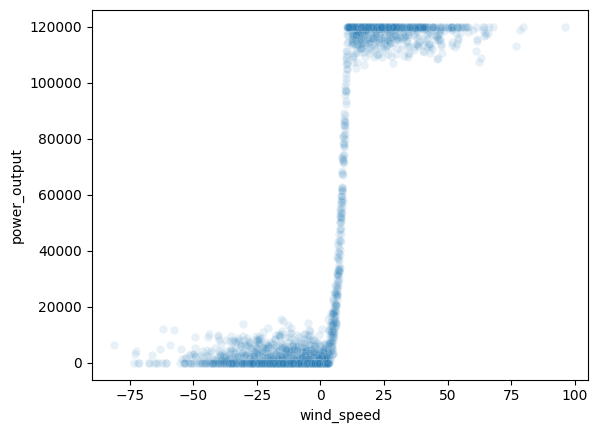

In [7]:
#checking the realationship between wind speed and power output
#does x actually influence y?

sns.scatterplot(x='wind_speed', y='power_output', data=df, alpha=0.1)

<Axes: xlabel='wind_speed', ylabel='power_output'>

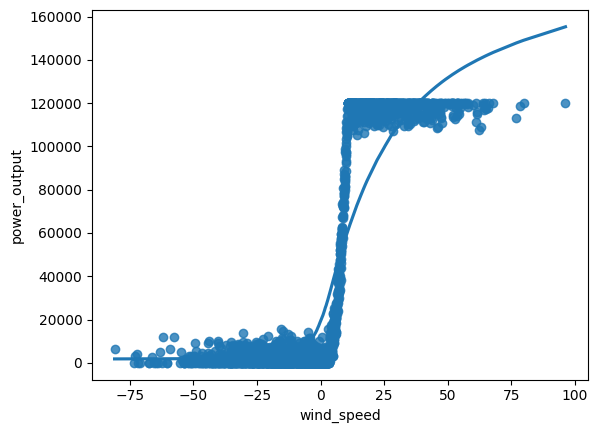

In [8]:
import seaborn as sns
sns.regplot(x='wind_speed', y='power_output', data=df, lowess=True)

<Axes: xlabel='wind_speed', ylabel='power_output'>

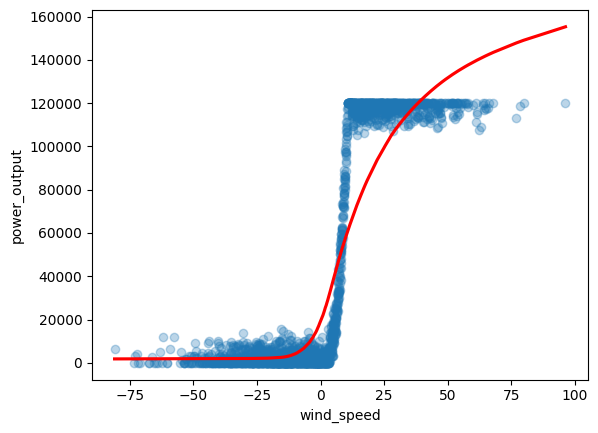

In [9]:
sns.regplot(x='wind_speed', y='power_output', data=df, lowess=True,
            scatter_kws={'alpha': 0.3}, line_kws={'color': 'red'})

In [10]:
#this shows that the relationship is non-linear with saturation,satisfyin our 
#initial guess.

df['power_output'].max()

np.float64(120000.0)

In [11]:
df['power_output'].skew()

np.float64(0.4830864341400566)

In [12]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
#preparing data
X = df[['wind_speed']]
y = df['power_output']

#splitting data
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)


In [13]:
#training the model
model = LinearRegression()
model.fit(X_train, y_train)

#predicting
y_pred = model.predict(X_test)


In [14]:

#evaluating the model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f'Mean Squared Error: {mse:.2f}')
print(f'R^2 Score: {r2:.4f}')

Mean Squared Error: 1025474733.95
R^2 Score: 0.6521


In [15]:
#the mean squared error is quite high, and the R^2 score is low, indicating that the linear model does not fit the data well, which is expected given the non-linear relationship between wind speed and power output.

<Axes: ylabel='power_output'>

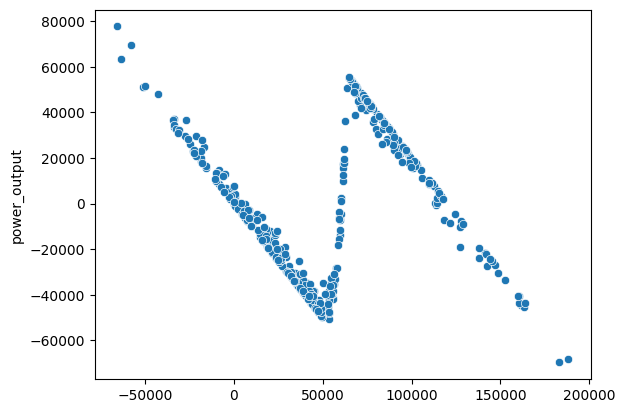

In [16]:
residuals = y_test - y_pred
sns.scatterplot(x=y_pred, y=residuals)

In [17]:
#this diagraom shows that the residuals are not randomly distributed, indicating that the linear model is not capturing the non-linear relationship between wind speed and power output effectively.    


In [ ]:
from sklearn.ensemble import RandomForestRegressor 
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures

degree = 3
poly_model = Pipeline([
    ('poly_features', PolynomialFeatures(degree=degree)),
    ('LinearRegression', LinearRegression())
])

poly_model .fit(X_train, y_train)
y_poly_pred = poly_model.predict(X_test)

In [22]:
mse = mean_squared_error(y_test, y_poly_pred)
r2 = r2_score(y_test, y_poly_pred)
print(f'Mean Squared Error: {mse:.2f}')
print(f'R^2 Score: {r2:.4f}')

Mean Squared Error: 644334581.75
R^2 Score: 0.7814


<Axes: ylabel='power_output'>

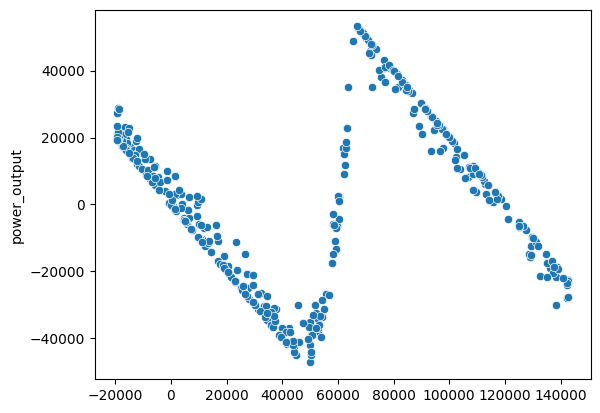

In [24]:
residuals = y_test - y_poly_pred
sns.scatterplot(x=y_poly_pred, y=residuals)


In [25]:
#using random forest regressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
y_rf_pred = rf_model.predict(X_test)



In [26]:
mse = mean_squared_error(y_test, y_rf_pred)
r2 = r2_score(y_test, y_rf_pred)
print(f'Mean Squared Error: {mse:.2f}')
print(f'R^2 Score: {r2:.4f}')


Mean Squared Error: 15221363.83
R^2 Score: 0.9948


<Axes: ylabel='power_output'>

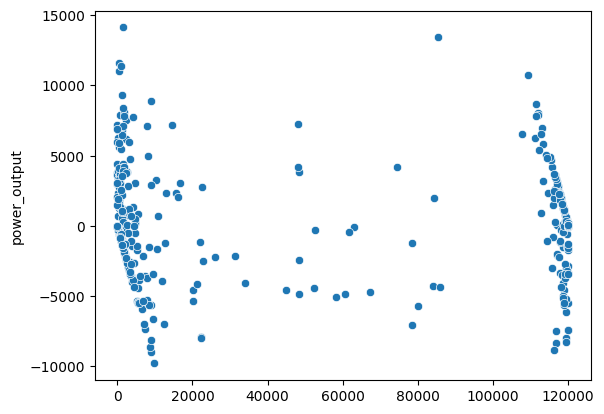

In [27]:
residuals = y_test - y_rf_pred
sns.scatterplot(x=y_rf_pred, y=residuals)

In [28]:
#feature importance : how much weight the model is giving to wind speed vs other
feature_importance = rf_model.feature_importances_
print(f'Feature Importance: {feature_importance}')

Feature Importance: [1.]


In [29]:
%pip install --upgrade xgboost

   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.8/101.7 MB 5.8 MB/s eta 0:00:18
    --------------------------------------- 1.8/101.7 MB 6.0 MB/s eta 0:00:17
   - -------------------------------------- 3.1/101.7 MB 6.0 MB/s eta 0:00:17
   - -------------------------------------- 4.5/101.7 MB 6.0 MB/s eta 0:00:17
   -- ------------------------------------- 5.8/101.7 MB 6.0 MB/s eta 0:00:16
   -- ------------------------------------- 7.1/101.7 MB 6.0 MB/s eta 0:00:16
   --- ------------------------------------ 8.4/101.7 MB 6.0 MB/s eta 0:00:16
   --- ------------------------------------ 9.7/101.7 MB 6.0 MB/s eta 0:00:16
   ---- ----------------------------------- 10.7/101.7 MB 5.9 MB/s eta 0:00:16
   ---- ----------------------------------- 11.5/101.7 MB 5.6 MB/s eta 0:00:16
   ----- ---------------------------------- 13.4/101.7 MB 5.9 MB/s eta 0:00:16
   ----- ---------------------------------- 14.4/101.7 MB 5.9 MB/s e


[notice] A new release of pip is available: 25.1.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [30]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(n_estimators=100, random_state=42)
xgb_model.fit(X_train, y_train)
y_xgb_pred = xgb_model.predict(X_test)



In [38]:
from sklearn.metrics import mean_absolute_error


mse = mean_squared_error(y_test, y_xgb_pred)
r2 = r2_score(y_test, y_xgb_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_xgb_pred))
mae = mean_absolute_error(y_test, y_xgb_pred)
r2 = r2_score(y_test, y_xgb_pred)
print(f'Mean Squared Error: {mse:.2f}')
print(f'R^2 Score: {r2:.4f}')
print(f'Root Mean Squared Error: {rmse:.2f}')
print(f'Mean Absolute Error: {mae:.2f}')

Mean Squared Error: 11832170.63
R^2 Score: 0.9960
Root Mean Squared Error: 3439.79
Mean Absolute Error: 2640.65


<Axes: ylabel='power_output'>

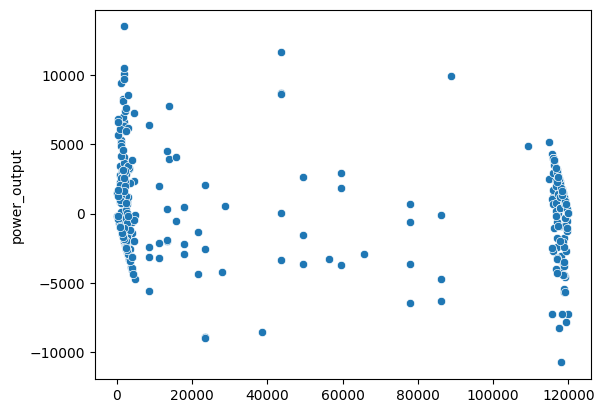

In [33]:
residuals = y_test - y_xgb_pred
sns.scatterplot(x=y_xgb_pred, y=residuals)

In [39]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(xgb_model, X, y, cv=5, scoring='r2')

# 2. Print the results
print(f"All CV R^2 Scores: {cv_scores}")
print(f"Mean R^2 Score: {np.mean(cv_scores):.4f}")
print(f"Standard Deviation: {np.std(cv_scores):.4f}")


All CV R^2 Scores: [0.99582376 0.99590968 0.99595129 0.99556941 0.99575432]
Mean R^2 Score: 0.9958
Standard Deviation: 0.0001
